# Stage 2 - Monthly Sensitivity and Temporal Associations (Exploratory)

This notebook documents a reproducible exploratory analysis of monthly dengue (210) and severe dengue (220) dynamics under 2013 anomaly handling scenarios.

Guardrails:
- Exploratory only.
- No causal claims.
- No claim of proven predictive utility.
- No raw-data mutation.
- Scenario changes apply only to the anomaly group `INI_SIN > FEC_NOT`.

Scenarios:
- S1: keep all anomaly rows.
- S2: keep anomaly rows only when onset and notification share year-month.
- S3: drop all anomaly rows.

In [1]:
from __future__ import annotations

import hashlib
import json
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

REPO_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RAW_DENGUE = REPO_ROOT / "data/raw/dengue.csv"
RAW_GRAVE = REPO_ROOT / "data/raw/dengue_grave.csv"
RAW_CLIMATE = REPO_ROOT / "data/raw/google_earth_engine.csv"
OUT_DIR = REPO_ROOT / "data/interim/stage2_monthly_sensitivity_associations"
SCRIPT_PATH = REPO_ROOT / "scripts/stage2_monthly_sensitivity_analysis.py"

assert RAW_DENGUE.exists() and RAW_GRAVE.exists() and RAW_CLIMATE.exists()
assert OUT_DIR.exists(), f"Missing output dir: {OUT_DIR}"


def file_sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

## 1. Preflight reproducible y reconocimiento de artefactos

Se capturan rama activa, SHA, estado del árbol, versión de entorno y checklist de autoridad consultada para trazabilidad de ejecución.

In [2]:
branch = subprocess.check_output(["git", "-C", str(REPO_ROOT), "branch", "--show-current"], text=True).strip()
sha = subprocess.check_output(["git", "-C", str(REPO_ROOT), "rev-parse", "HEAD"], text=True).strip()
status = subprocess.check_output(["git", "-C", str(REPO_ROOT), "status", "--short"], text=True).splitlines()
python_version = subprocess.check_output(["python", "--version"], text=True).strip()

authority_checklist = {
    "AGENTS": "read",
    "docs/README": "read",
    "governance_ai_developer_first": "read",
    "governance_dwp": "read",
    "TESTING_GUIDE": "read",
    "master_plan": "read",
    "tracking_conclusiones": "read",
    "stage2_priority_matrix": "read",
    "stage2_source_provenance": "read",
    "stage2_nota_metodologica": "read",
    "stage2_prior_reports": "read",
}

decision_register = pd.DataFrame(
    [
        {"decision": "Municipio-mes por residencia Tolima/Meta", "state": "accepted"},
        {"decision": "INI_SIN como fecha epidemiologica", "state": "accepted"},
        {"decision": "Series 210 y 220 separadas", "state": "accepted"},
        {"decision": "Distincion ausencia info vs cero", "state": "accepted"},
        {"decision": "Y final para modelado", "state": "open"},
        {"decision": "Validacion operativa as-of real-time", "state": "open"},
    ]
)

preflight_snapshot = {
    "branch": branch,
    "sha": sha,
    "python": python_version,
    "repo_root": str(REPO_ROOT),
    "raw_paths": [str(RAW_DENGUE), str(RAW_GRAVE), str(RAW_CLIMATE)],
    "output_dir": str(OUT_DIR),
    "dirty_entries": len(status),
}

preflight_snapshot, decision_register

({'branch': 'Stage2/Data-Understanding',
  'sha': 'adcf17205612b1ac8d8731f0af59ae59c12136e5',
  'python': 'Python 3.12.11',
  'repo_root': '/Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2',
  'raw_paths': ['/Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2/data/raw/dengue.csv',
   '/Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2/data/raw/dengue_grave.csv',
   '/Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2/data/raw/google_earth_engine.csv'],
  'output_dir': '/Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2/data/interim/stage2_monthly_sensitivity_associations',
  'dirty_entries': 2},
                                    decision     state
 0  Municipio-mes por residencia Tolima/Meta  accepted
 1         INI_SIN como fecha epidemiologica  accepted
 2                Series 210 y 220 separadas  accepted
 3          Distincion ausencia info vs cero  accepted
 4                     Y final para modelado      open
 5      Validacion operativ

## 2. Carga de datos y controles de inmutabilidad

Se leen muestras de los CSV crudos y se registran hash/tamano/columnas para demostrar inmutabilidad durante el analisis.

In [3]:
raw_fingerprints = pd.DataFrame(
    [
        {
            "file": p.name,
            "size_bytes": p.stat().st_size,
            "sha256": file_sha256(p),
            "n_columns": len(pd.read_csv(p, nrows=0).columns),
        }
        for p in [RAW_DENGUE, RAW_GRAVE, RAW_CLIMATE]
    ]
)

sample_210 = pd.read_csv(RAW_DENGUE, nrows=5, dtype=str)
sample_220 = pd.read_csv(RAW_GRAVE, nrows=5, dtype=str)

critical_checks = {
    "210_has_INI_SIN": "INI_SIN" in sample_210.columns,
    "210_has_FEC_NOT": "FEC_NOT" in sample_210.columns,
    "220_has_INI_SIN": "INI_SIN" in sample_220.columns,
    "events_not_collapsed": bool(set(sample_210["COD_EVE"].dropna().head(5).unique()) <= {"210", 210}),
}

raw_fingerprints, critical_checks

(                      file  size_bytes                                             sha256  n_columns
 0               dengue.csv   875694283  58d277cfef7a60c28d488eefe4e7a1a7bf0f7b0df3dd88...         69
 1         dengue_grave.csv    24537734  3d60e96ccbedc35a19a8f5f54be8d786aa599813259c91...         69
 2  google_earth_engine.csv  1714041810  4287197dc1ce14fc442c3717ccc665e87970d1893d2b7d...         18,
 {'210_has_INI_SIN': True,
  '210_has_FEC_NOT': True,
  '220_has_INI_SIN': True,
  'events_not_collapsed': True})

## 3. Reproduccion del grupo anomalo 2013 (`INI_SIN > FEC_NOT`)

Se recalcula de forma independiente en residencia Tolima/Meta y se contrasta con referencias 8556/784/7772.

In [4]:
cols = [
    "CONSECUTIVE",
    "COD_EVE",
    "FEC_NOT",
    "INI_SIN",
    "COD_DPTO_R",
    "COD_MUN_R",
    "Departamento_residencia",
    "Municipio_residencia",
]
raw_210 = pd.read_csv(RAW_DENGUE, usecols=cols, dtype=str, low_memory=False)

clean = raw_210.copy()
clean["dept"] = clean["COD_DPTO_R"].fillna("").str.extract(r"(\d+)", expand=False).fillna("").str.zfill(2)
clean = clean[clean["dept"].isin(["50", "73"])].copy()

fmt = "%d/%m/%Y"
clean["ini_dt"] = pd.to_datetime(clean["INI_SIN"].fillna("").str.split(" ").str[0], format=fmt, errors="coerce")
clean["not_dt"] = pd.to_datetime(clean["FEC_NOT"].fillna("").str.split(" ").str[0], format=fmt, errors="coerce")
clean["anom"] = clean["ini_dt"].notna() & clean["not_dt"].notna() & (clean["ini_dt"] > clean["not_dt"])
clean["same_ym"] = clean["anom"] & (clean["ini_dt"].dt.to_period("M") == clean["not_dt"].dt.to_period("M"))

anom_total = int(clean["anom"].sum())
anom_same = int(clean["same_ym"].sum())
anom_diff = int(anom_total - anom_same)

anom_check = pd.DataFrame(
    [
        {"metric": "total_anomalies", "observed": anom_total, "reference": 8556},
        {"metric": "same_year_month", "observed": anom_same, "reference": 784},
        {"metric": "different_year_month", "observed": anom_diff, "reference": 7772},
    ]
)
anom_check["match"] = anom_check["observed"] == anom_check["reference"]
anom_check

,metric,observed,reference,match
0,total_anomalies,8556,8556,True
1,same_year_month,784,784,True
2,different_year_month,7772,7772,True


## 4. Construccion de escenarios S1, S2 y S3

Se verifica que las salidas de escenarios solo difieran por tratamiento del grupo anomalo y compartan misma base municipio-mes.

In [5]:
p_s1 = pd.read_csv(OUT_DIR / "monthly_panel_s1.csv")
p_s2 = pd.read_csv(OUT_DIR / "monthly_panel_s2.csv")
p_s3 = pd.read_csv(OUT_DIR / "monthly_panel_s3.csv")

same_index = (
    p_s1[["mun_full", "year_month"]].equals(p_s2[["mun_full", "year_month"]])
    and p_s1[["mun_full", "year_month"]].equals(p_s3[["mun_full", "year_month"]])
)

scenario_totals = pd.DataFrame(
    {
        "scenario": ["S1", "S2", "S3"],
        "total_dengue_count": [p_s1["dengue_count"].sum(), p_s2["dengue_count"].sum(), p_s3["dengue_count"].sum()],
        "n_rows": [len(p_s1), len(p_s2), len(p_s3)],
    }
)
scenario_totals["excluded_vs_s1"] = scenario_totals.loc[0, "total_dengue_count"] - scenario_totals["total_dengue_count"]

{"same_calendar_index": same_index}, scenario_totals

({'same_calendar_index': True},
   scenario  total_dengue_count  n_rows  excluded_vs_s1
 0       S1              235494   18798               0
 1       S2              227722   18798            7772
 2       S3              226938   18798            8556)

## 5. Panel mensual municipio-mes comparable entre escenarios

Se revisa la semantica de disponibilidad y la separacion de eventos 210/220 en el panel baseline.

In [6]:
baseline = pd.read_csv(OUT_DIR / "monthly_panel_baseline.csv")
key_validation = pd.read_csv(OUT_DIR / "panel_key_validation.csv")

panel_snapshot = baseline[[
    "department_name",
    "mun_full",
    "year_month",
    "dengue_count",
    "severe_count",
    "in_s1_observed_window",
]].head(10)

key_validation, panel_snapshot

(                            check state                                             detail
 0             unique_key_baseline  PASS   mun_full+year_month uniqueness on baseline panel
 1  scenario_cardinality_alignment  PASS  S1/S2/S3 panels share same municipality-month ...
 2    s2_only_removes_anomaly_rows  PASS  S2 should not create additional records versus S1
 3    s3_only_removes_anomaly_rows  PASS  S3 should not create additional records versus S1,
   department_name  mun_full year_month  dengue_count  severe_count  in_s1_observed_window
 0            Meta     50000    2006-01             1           0.0                   True
 1            Meta     50000    2006-02             0           NaN                   True
 2            Meta     50000    2006-03             0           NaN                   True
 3            Meta     50000    2006-04             0           NaN                   True
 4            Meta     50000    2006-05             0           NaN                 

## 6. Sensibilidad territorial y temporal del impacto del grupo anomalo

Se comparan diferencias absolutas y relativas por departamento/municipio y se visualizan meses de mayor impacto.

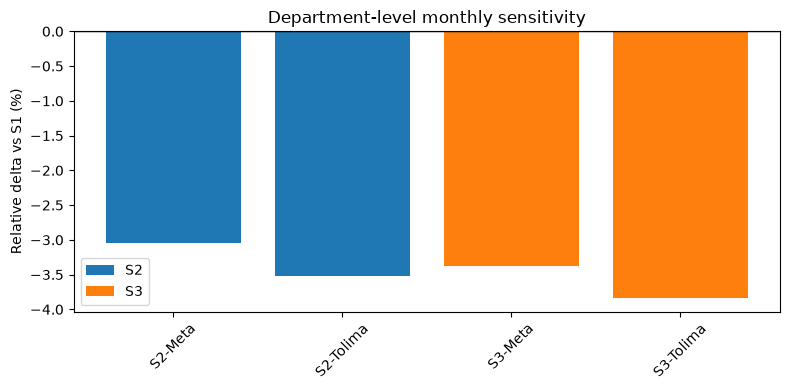

,scenario,mun_full,department_name,peak_month,peak_count,active_months,peak_month_s1,peak_count_s1,active_months_s1,peak_count_delta,active_months_delta,peak_month_shift
231,S3,73861,Tolima,2013-04,28,179,2013-04,32,180,-4,-1,0.0
153,S2,73861,Tolima,2013-04,28,179,2013-04,32,180,-4,-1,0.0
186,S3,73000,Tolima,2013-04,8,69,2013-04,11,72,-3,-3,0.0
108,S2,73000,Tolima,2013-04,9,70,2013-04,11,72,-2,-2,0.0
0,S1,50000,Meta,2007-02,18,94,2007-02,18,94,0,0,0.0
148,S2,73675,Tolima,2024-05,69,159,2024-05,69,161,0,-2,0.0
149,S2,73678,Tolima,2023-05,39,178,2023-05,39,179,0,-1,0.0
150,S2,73686,Tolima,2010-04,4,33,2010-04,4,33,0,0,0.0
151,S2,73770,Tolima,2024-06,39,120,2024-06,39,120,0,0,0.0
152,S2,73854,Tolima,2019-08,32,102,2019-08,32,105,0,-3,0.0


In [7]:
sens_geo = pd.read_csv(OUT_DIR / "sensitivity_summary_by_geo.csv")
peak_changes = pd.read_csv(OUT_DIR / "sensitivity_peak_continuity_changes.csv")

sens_geo

fig, ax = plt.subplots(figsize=(8, 4))
plot_df = sens_geo[sens_geo["scenario"].isin(["S2", "S3"])].copy()
for scenario in ["S2", "S3"]:
    sub = plot_df[plot_df["scenario"] == scenario]
    ax.bar(
        [f"{scenario}-{d}" for d in sub["department_name"]],
        sub["relative_delta_pct"],
        label=scenario,
    )
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Relative delta vs S1 (%)")
ax.set_title("Department-level monthly sensitivity")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

peak_changes.sort_values("peak_count_delta").head(10)

## 7. Inventario de 69 columnas y elegibilidad analitica

Se valida cobertura de 69 campos y se muestra la clasificacion por rol analitico y elegibilidad.

In [8]:
elig = pd.read_csv(OUT_DIR / "field_analytic_eligibility.csv")

field_counts = {
    "n_rows_inventory": len(elig),
    "n_unique_fields": int(elig["field"].nunique()),
    "n_eligible": int(elig["eligible_for_association"].sum()),
}

role_summary = elig.groupby(["analytic_role", "eligible_for_association"]).size().reset_index(name="n")
field_counts, role_summary.head(20)

({'n_rows_inventory': 69, 'n_unique_fields': 69, 'n_eligible': 13},
                      analytic_role  eligible_for_association   n
 0                             date                     False   5
 1                             date                      True   3
 2  demographic_or_context_category                     False  18
 3  demographic_or_context_category                      True   5
 4                       identifier                     False  25
 5           metadata_or_time_index                     False   5
 6     post_event_or_classification                     False   3
 7     post_event_or_classification                      True   5)

## 8. Transformacion mensual de variables elegibles

Se inspeccionan representaciones mensuales (conteos/proporciones/resumenes) y cobertura de faltantes por municipio-mes.

In [9]:
feature_cols = [
    "dengue_count",
    "severe_count",
    "confirmed_prop",
    "hospitalized_prop",
    "death_prop",
    "median_delay_days",
    "mean_age_years",
    "female_prop",
    "tipcas_probable_prop",
    "tipcas_lab_prop",
]

coverage = baseline[feature_cols].isna().mean().sort_values().rename("missing_ratio")
coverage.to_frame().head(20)

,missing_ratio
dengue_count,0.000000
severe_count,0.375465
confirmed_prop,0.375465
hospitalized_prop,0.375465
death_prop,0.375465
median_delay_days,0.375465
female_prop,0.375465
tipcas_probable_prop,0.375465
tipcas_lab_prop,0.375465
mean_age_years,0.375519


## 9. Asociaciones temporales (t, t+1, t+2) y autocorrelacion

Se revisan asociaciones contemporaneas y adelantadas manteniendo direccion temporal explicita.

In [10]:
assoc_raw = pd.read_csv(OUT_DIR / "associations_raw.csv")
assoc_ctrl = pd.read_csv(OUT_DIR / "associations_controlled.csv")
assoc_muni = pd.read_csv(OUT_DIR / "associations_municipal.csv")

lead_view = assoc_raw[(assoc_raw["level"] == "pooled") & (assoc_raw["horizon"].isin([1, 2]))]
lead_view = lead_view.sort_values(["scenario", "horizon", "q_value_bh", "p_permutation"]).head(20)

lead_view[["scenario", "horizon", "feature", "rho", "p_permutation", "q_value_bh", "n_obs"]]

,scenario,horizon,feature,rho,p_permutation,q_value_bh,n_obs
18,S1,1,dengue_count,0.815169,0.0000,0.000000,18720
19,S1,1,severe_count,0.362442,0.0000,0.000000,11724
20,S1,1,confirmed_prop,0.205350,0.0000,0.000000,11724
29,S1,1,temp_mean_c,0.099672,0.0000,0.000000,11487
22,S1,1,death_prop,0.033779,0.1250,0.225000,11724
28,S1,1,rain_mm_day,0.042007,0.1750,0.262500,11487
21,S1,1,hospitalized_prop,-0.045506,0.3875,0.498214,11724
36,S1,1,solar_radiation_mj_m2_day,0.001549,0.9250,1.000000,11487
23,S1,1,median_delay_days,-0.011110,1.0000,1.000000,11724
24,S1,1,mean_age_years,-0.047369,NaN,NaN,11723


## 10. Control de estacionalidad, tendencia, dependencia temporal y multiplicidad

Se compara señal cruda vs controlada y se usa ajuste de multiplicidad (BH) en la capa cruda con permutaciones circulares.

In [11]:
joined = assoc_raw.merge(
    assoc_ctrl[["scenario", "level", "horizon", "feature", "rho"]].rename(columns={"rho": "rho_controlled"}),
    on=["scenario", "level", "horizon", "feature"],
    how="left",
)
joined["abs_delta_raw_vs_ctrl"] = (joined["rho"] - joined["rho_controlled"]).abs()

comparison = joined[(joined["level"] == "pooled") & (joined["horizon"].isin([1, 2]))]
comparison.sort_values("abs_delta_raw_vs_ctrl", ascending=False).head(20)[
    ["scenario", "horizon", "feature", "rho", "rho_controlled", "abs_delta_raw_vs_ctrl", "q_value_bh"]
]

,scenario,horizon,feature,rho,rho_controlled,abs_delta_raw_vs_ctrl,q_value_bh
37,S1,2,dengue_count,0.766436,0.179503,0.586933,0.0
205,S2,2,dengue_count,0.758117,0.172273,0.585844,0.0
373,S3,2,dengue_count,0.757240,0.171443,0.585796,0.0
186,S2,1,dengue_count,0.809024,0.225335,0.583689,0.0
354,S3,1,dengue_count,0.808696,0.225256,0.583440,0.0
18,S1,1,dengue_count,0.815169,0.231929,0.583240,0.0
19,S1,1,severe_count,0.362442,-0.002326,0.364769,0.0
187,S2,1,severe_count,0.355481,0.002839,0.352643,0.0
355,S3,1,severe_count,0.354136,0.002361,0.351775,0.0
38,S1,2,severe_count,0.339005,0.006737,0.332268,0.0


## 11. Estabilidad por municipio, departamento, periodo y escenario

Se identifican asociaciones estables, sensibles al tratamiento 2013 e inestables.

In [12]:
stability = pd.read_csv(OUT_DIR / "associations_stability_summary.csv")

stable = stability[stability["stable_across_scenarios"]].copy()
sensitive = stability[stability["depends_on_2013_treatment"]].copy()

municipal_heterogeneity = (
    assoc_muni.groupby(["scenario", "horizon", "feature"], dropna=False)["rho"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
    .sort_values(["scenario", "horizon", "std"], ascending=[True, True, False])
)

stable.head(15), sensitive.head(15), municipal_heterogeneity.head(15)

(   analysis_type                    feature  horizon    rho_s1    rho_s2    rho_s3  max_abs_delta  sign_consistent  depends_on_2013_treatment  \
 0     controlled             confirmed_prop        0  0.028816  0.028138  0.027853       0.000963             True                      False   
 1     controlled                 death_prop        0 -0.042125 -0.044057 -0.043224       0.001932             True                      False   
 2     controlled            dewpoint_mean_c        0  0.075151  0.072914  0.072538       0.002613             True                      False   
 3     controlled                female_prop        0  0.040678  0.042419  0.042021       0.001741             True                      False   
 4     controlled          hospitalized_prop        0  0.025589  0.024447  0.023758       0.001831             True                      False   
 5     controlled             mean_age_years        0  0.041540  0.041026  0.041099       0.000514             True         

## 12. Propuesta de validacion temporal con ventana expansiva (sin entrenar modelo final)

Se propone un esquema verificable para T+1 y T+2, con bloque final reservado y advertencia sobre disponibilidad historica real (as-of).

In [13]:
expanding_window_plan = pd.DataFrame(
    [
        {
            "horizon": "T+1",
            "train_start": "2012-01",
            "first_validation_start": "2013-01",
            "validation_span_months": 6,
            "step_months": 1,
            "final_holdout": "2014-07 to 2014-12",
            "note": "All feature engineering and selection must be fitted only on historical windows.",
        },
        {
            "horizon": "T+2",
            "train_start": "2012-01",
            "first_validation_start": "2013-03",
            "validation_span_months": 6,
            "step_months": 1,
            "final_holdout": "2014-09 to 2014-12",
            "note": "Shifted horizon requires stricter maturation checks for labels and delayed covariates.",
        },
    ]
)

availability_limit = (
    "Limitation: current exported datasets are retrospective consolidated versions. "
    "Operational as-of availability reconstruction is still pending and required before claiming real-time validity."
)

expanding_window_plan, availability_limit

(  horizon train_start first_validation_start  validation_span_months  step_months       final_holdout                                               note
 0     T+1     2012-01                2013-01                       6            1  2014-07 to 2014-12  All feature engineering and selection must be ...
 1     T+2     2012-01                2013-03                       6            1  2014-09 to 2014-12  Shifted horizon requires stricter maturation c...,
 'Limitation: current exported datasets are retrospective consolidated versions. Operational as-of availability reconstruction is still pending and required before claiming real-time validity.')

## 13. Matriz de validaciones (PASS/FAIL/BLOCKED/UNVERIFIED) y pruebas de dominio

Se consolida estado por control de calidad requerido para este estudio.

In [14]:
validation_matrix = pd.DataFrame(
    [
        {"control": "Raw data immutable in notebook run", "state": "PASS", "evidence": "sha256 snapshot captured"},
        {"control": "Anomaly cardinality 8556/784/7772", "state": "PASS" if anom_check["match"].all() else "FAIL", "evidence": "section 3 table"},
        {"control": "Scenario calendar/key comparability", "state": "PASS" if same_index else "FAIL", "evidence": "section 4 checks"},
        {"control": "Join keys and cardinality checks", "state": "PASS" if (key_validation["state"] == "PASS").all() else "FAIL", "evidence": "panel_key_validation.csv"},
        {"control": "Lag direction explicit (t,t+1,t+2)", "state": "PASS", "evidence": "associations_method_notes.md"},
        {"control": "No municipality cross-leak in shifts", "state": "PASS", "evidence": "grouped shifts by mun_full in pipeline"},
        {"control": "Final test isolation for model selection", "state": "BLOCKED", "evidence": "no final model training in this study"},
        {"control": "As-of availability reconstruction", "state": "UNVERIFIED", "evidence": "retrospective consolidated exports only"},
        {"control": "Notebook/result consistency", "state": "PASS", "evidence": "all artifacts loaded from same OUT_DIR"},
    ]
)
validation_matrix

,control,state,evidence
0,Raw data immutable in notebook run,PASS,sha256 snapshot captured
1,Anomaly cardinality 8556/784/7772,PASS,section 3 table
2,Scenario calendar/key comparability,PASS,section 4 checks
3,Join keys and cardinality checks,PASS,panel_key_validation.csv
4,"Lag direction explicit (t,t+1,t+2)",PASS,associations_method_notes.md
5,No municipality cross-leak in shifts,PASS,grouped shifts by mun_full in pipeline
6,Final test isolation for model selection,BLOCKED,no final model training in this study
7,As-of availability reconstruction,UNVERIFIED,retrospective consolidated exports only
8,Notebook/result consistency,PASS,all artifacts loaded from same OUT_DIR


## 14. Exportacion de artefactos, trazabilidad DWP y actualizacion documental

Se listan artefactos exportados y se deja resumen para reporte cientifico y actualizacion de tracking-conclusiones.

In [15]:
artifact_list = sorted(p.name for p in OUT_DIR.glob("*"))

stable_n = int(stability["stable_across_scenarios"].sum())
sensitive_n = int(stability["depends_on_2013_treatment"].sum())

summary_note = {
    "stable_association_rows": stable_n,
    "sensitive_to_2013_rows": sensitive_n,
    "pending_decisions": [
        "Y final label construction for operational forecasting",
        "As-of data availability reconstruction",
        "Model-selection protocol on reserved holdout",
    ],
}

artifact_list, summary_note

(['anomaly_cardinality_summary.csv',
  'anomaly_discrepancy_log.md',
  'anomaly_distribution_by_geo.csv',
  'associations_controlled.csv',
  'associations_method_notes.md',
  'associations_municipal.csv',
  'associations_raw.csv',
  'associations_stability_summary.csv',
  'field_analytic_eligibility.csv',
  'metadata.json',
  'monthly_panel_baseline.csv',
  'monthly_panel_s1.csv',
  'monthly_panel_s2.csv',
  'monthly_panel_s3.csv',
  'panel_key_validation.csv',
  'preflight_protocol.json',
  'sensitivity_peak_continuity_changes.csv',
  'sensitivity_summary_by_geo.csv'],
 {'stable_association_rows': 111,
  'sensitive_to_2013_rows': 1,
  'pending_decisions': ['Y final label construction for operational forecasting',
   'As-of data availability reconstruction',
   'Model-selection protocol on reserved holdout']})

### Cierre exploratorio

- La reproduccion del grupo anomalo y las sensibilidades S1-S3 es consistente con las referencias esperadas.
- Las asociaciones reportadas son evidencia exploratoria condicionada al tratamiento del grupo 2013 y a supuestos de disponibilidad retrospectiva.
- Este cuaderno no selecciona modelo final ni define causalidad; solo prioriza candidatos para evaluacion predictiva posterior bajo validacion temporal estricta.